In [1]:
import numpy as np
import pandas as pd

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].asfreq("MS").astype(float)

# Train-test split
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

# SARIMA configurations
models = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((1, 1, 2), (1, 1, 1, 12)),
    ((2, 1, 1), (1, 1, 1, 12))
]

results = []

for order, seasonal_order in models:

    model = SARIMAX(
        train,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False)

    forecast = fitted.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        "Order": order,
        "Seasonal Order": seasonal_order,
        "AIC": fitted.aic,
        "MAE": mae,
        "RMSE": rmse
    })

result_df = pd.DataFrame(results)

print(result_df)

       Order Seasonal Order         AIC        MAE       RMSE
0  (1, 1, 1)  (1, 1, 1, 12)  657.601346  25.268045  31.787297
1  (1, 1, 2)  (1, 1, 1, 12)  653.509911  26.063772  32.574529
2  (2, 1, 1)  (1, 1, 1, 12)  659.252153  26.495758  32.989442


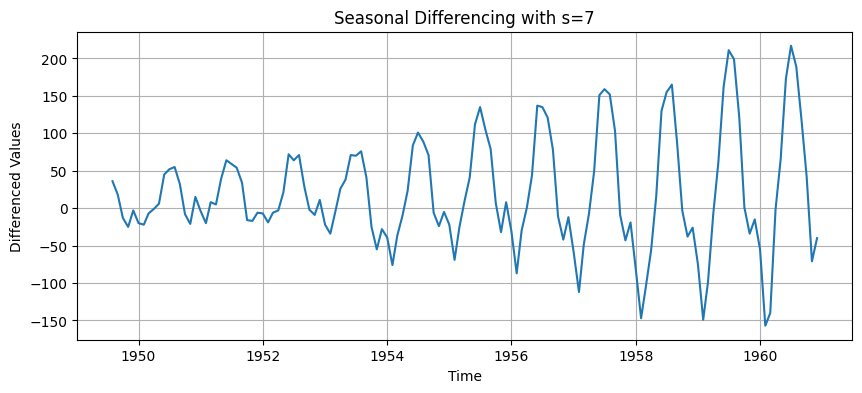

Seasonal period: 7
Number of observations: 137


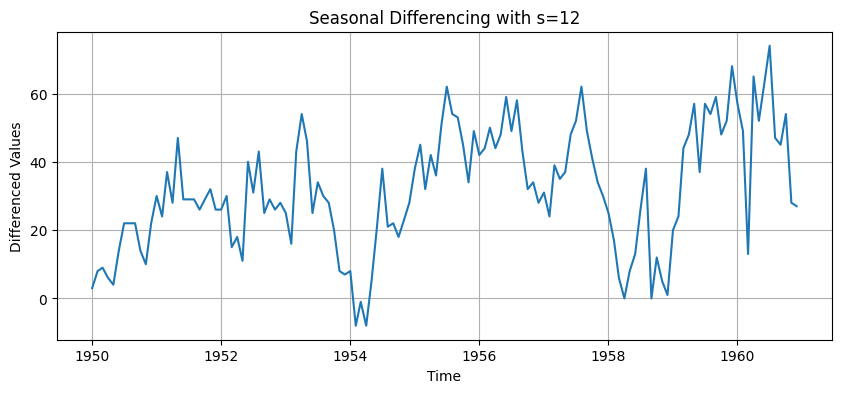

Seasonal period: 12
Number of observations: 132


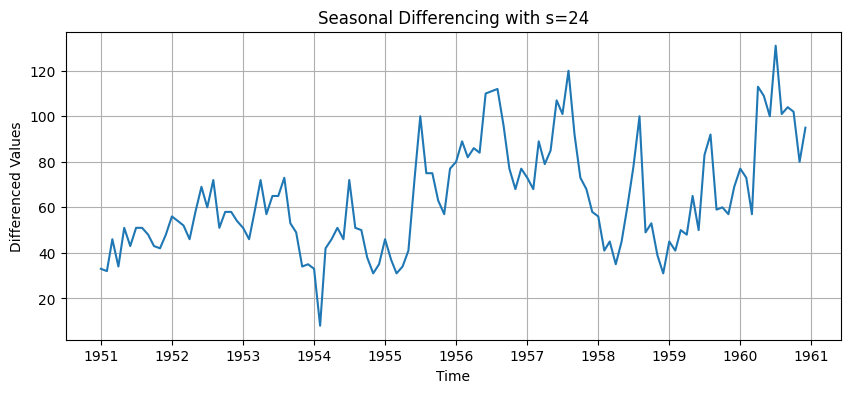

Seasonal period: 24
Number of observations: 120


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load monthly AirPassengers dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].asfreq("MS").astype(float)

# Different seasonal periods
periods = [7, 12, 24]

for s in periods:

    seasonal_diff = series.diff(s).dropna()

    plt.figure(figsize=(10, 4))
    plt.plot(seasonal_diff)

    plt.title(f"Seasonal Differencing with s={s}")
    plt.xlabel("Time")
    plt.ylabel("Differenced Values")
    plt.grid()
    plt.show()

    print(f"Seasonal period: {s}")
    print(f"Number of observations: {len(seasonal_diff)}")

    Model        MAE       RMSE
0   ARIMA  63.545311  82.513011
1  SARIMA  25.268045  31.787297


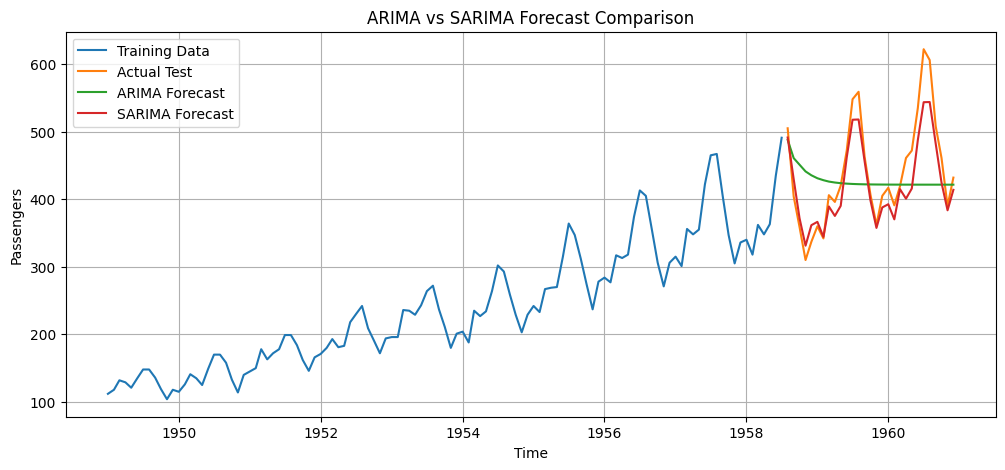

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].asfreq("MS").astype(float)

# Train-test split
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

# ARIMA model
arima_model = ARIMA(train, order=(2, 1, 2))
arima_fit = arima_model.fit()

arima_forecast = arima_fit.forecast(steps=len(test))

# SARIMA model
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False)

sarima_forecast = sarima_fit.forecast(steps=len(test))

# Calculate errors
results = pd.DataFrame({
    "Model": ["ARIMA", "SARIMA"],
    "MAE": [
        mean_absolute_error(test, arima_forecast),
        mean_absolute_error(test, sarima_forecast)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(test, arima_forecast)),
        np.sqrt(mean_squared_error(test, sarima_forecast))
    ]
})

print(results)

# Plot comparison
plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Actual Test")
plt.plot(test.index, arima_forecast, label="ARIMA Forecast")
plt.plot(test.index, sarima_forecast, label="SARIMA Forecast")

plt.title("ARIMA vs SARIMA Forecast Comparison")
plt.xlabel("Time")
plt.ylabel("Passengers")
plt.legend()
plt.grid()
plt.show()

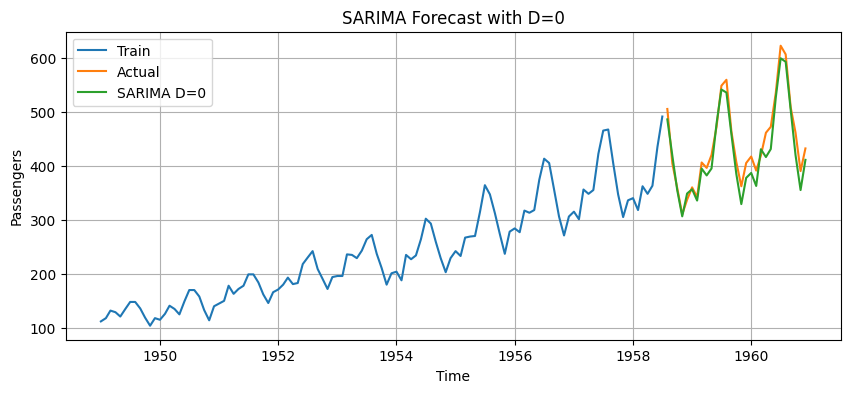

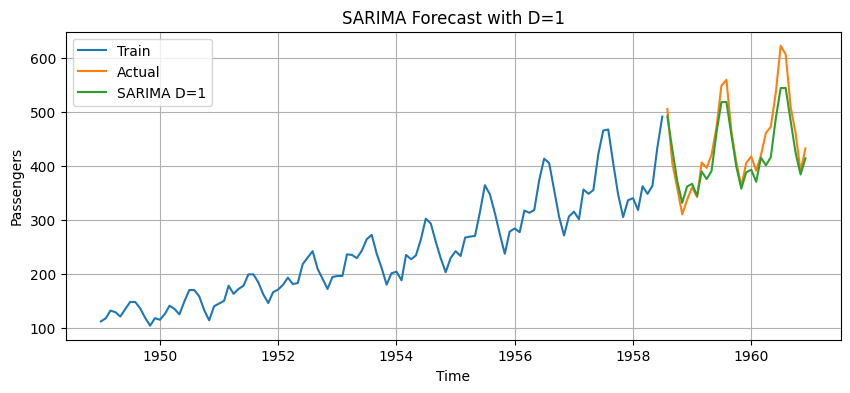

   Seasonal Differencing (D)         AIC        MAE       RMSE
0                          0  721.684158  18.697305  22.399172
1                          1  657.601346  25.268045  31.787297


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df["Month"] = pd.to_datetime(df["Month"])
df.set_index("Month", inplace=True)

series = df["Passengers"].asfreq("MS").astype(float)

# Train-test split
train_size = int(len(series) * 0.80)
train = series.iloc[:train_size]
test = series.iloc[train_size:]

results = []

for D in [0, 1]:

    model = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=(1, D, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False)

    forecast = fitted.forecast(steps=len(test))

    mae = mean_absolute_error(test, forecast)
    rmse = np.sqrt(mean_squared_error(test, forecast))

    results.append({
        "Seasonal Differencing (D)": D,
        "AIC": fitted.aic,
        "MAE": mae,
        "RMSE": rmse
    })

    # Plot forecast
    plt.figure(figsize=(10, 4))
    plt.plot(train.index, train, label="Train")
    plt.plot(test.index, test, label="Actual")
    plt.plot(test.index, forecast, label=f"SARIMA D={D}")

    plt.title(f"SARIMA Forecast with D={D}")
    plt.xlabel("Time")
    plt.ylabel("Passengers")
    plt.legend()
    plt.grid()
    plt.show()

# Compare results
print(pd.DataFrame(results))